<img src="../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# Clustering with K-Means

---

### About
Understand what unsupervised learning is, when to apply clustering, and perform a k-means clustering, evaluating cluster quality using Silhouette Coefficient and Inertia.

### Learning Objectives
- Know the difference between supervised and unsupervised learning.
- Understand when to use clustering.
- Perform a k-Means clustering analysis.
- Evaluate clusters for fit with Silhouette Coefficient and Inertia.

### Notebook Guide
- Imports
- Make Data
- Metrics for Assessing Clusters
- Using the elbow method to choose k
- Bonus Exercise: Old Faithful
- Conclusions and Takeaways

# Imports

In [202]:
from sklearn.datasets import make_blobs

#TODO: Import KMeans 
from sklearn.cluster import KMeans

from sklearn.preprocessing import StandardScaler

import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib

matplotlib.style.use('ggplot')

# Make Data
Let's make some more blobs to test K-Means on.

In [203]:
# Let's make some more blobs to test K-Means on
data, color = make_blobs(n_samples=100, random_state=42, centers=3, cluster_std=1.5)

df = pd.DataFrame(data, columns=["x1", "x2"])
df.head()

,x1,x2
0,-8.149818,-9.152380
1,5.860155,0.126873
2,-3.213409,9.828126
3,6.744070,-0.129607
4,-6.342946,-6.038933


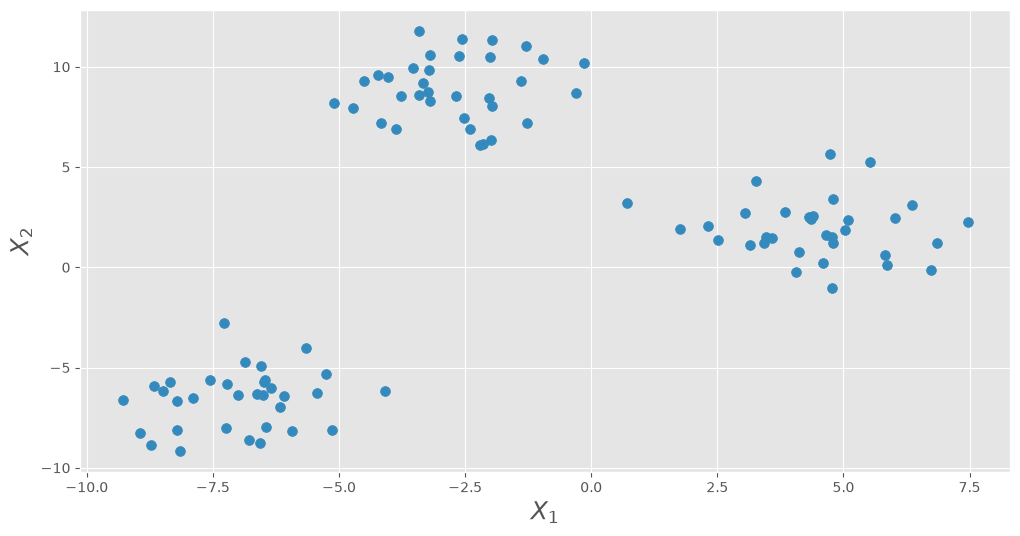

In [204]:
# Take a look at the data using a scatterplot
df.plot(kind="scatter", x="x1", y="x2", figsize=(12,6), s=50)

plt.xlabel("$X_1$", fontsize=18)
plt.ylabel("$X_2$", fontsize=18);

In [205]:
# TODO: Define X
X = df[['x1', 'x2']]

In [206]:
# There's a VERY important step before fitting our K-Means Model. Any ideas?

# TODO: Apply a transformation to X
sc = StandardScaler()

X_scaled = sc.fit_transform(X)

In [207]:
# TODO: Fit a K-means model with 3 clusters
# (use random_state=42 )

km = KMeans(
    n_clusters=3,
    random_state=42
)

km.fit(X_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 2)","[

## What did we discover?

### I. Cluster Predictions

In [208]:
# Option 1: Class attribute

# TODO: Show the labels for each obervation

km.labels_

array([1, 2, 0, 2, 1, 2, 0, 2, 2, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1,
       1, 0, 0, 0, 2, 1, 1, 1, 1, 2, 2, 1, 0, 0, 0, 0, 2, 2, 1, 0, 2, 0,
       0, 2, 1, 1, 1, 2, 2, 2, 0, 1, 1, 1, 0, 0, 2, 0, 1, 2, 1, 2, 1, 1,
       2, 1, 2, 2, 2, 1, 1, 0, 2, 1, 2, 1, 2, 2, 0, 2, 0, 1, 0, 0, 0, 2,
       0, 2, 2, 2, 0, 2, 0, 0, 0, 2, 1, 0], dtype=int32)

In [209]:
# Option 2: Predict

# TODO: Show the labels using the predict function

km.predict(X_scaled)

array([1, 2, 0, 2, 1, 2, 0, 2, 2, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1,
       1, 0, 0, 0, 2, 1, 1, 1, 1, 2, 2, 1, 0, 0, 0, 0, 2, 2, 1, 0, 2, 0,
       0, 2, 1, 1, 1, 2, 2, 2, 0, 1, 1, 1, 0, 0, 2, 0, 1, 2, 1, 2, 1, 1,
       2, 1, 2, 2, 2, 1, 1, 0, 2, 1, 2, 1, 2, 2, 0, 2, 0, 1, 0, 0, 0, 2,
       0, 2, 2, 2, 0, 2, 0, 0, 0, 2, 1, 0], dtype=int32)

In [210]:
# TODO: Attach predicted cluster to original points
# (Add a new column to your original dataframe, name it 'cluster')

df['cluster'] = km.labels_

df.head()

,x1,x2,cluster
0,-8.149818,-9.152380,1
1,5.860155,0.126873,2
2,-3.213409,9.828126,0
3,6.744070,-0.129607,2
4,-6.342946,-6.038933,1


### II. Centroids

In [211]:
# Option 1: Using groupby

df.groupby('cluster').mean()

,x1,x2
cluster,,
0,-2.747107,8.896498
1,-6.987751,-6.574270
2,4.429326,1.921795


In [212]:
# Option 2: (Preferred method) Using cluster_centers_

# TODO: Display the coordinates of each centroid

km.cluster_centers_

# But wait... why does this not match the one above?!

array([[-0.19912024,  1.13805994],
       [-1.07070258, -1.23896837],
       [ 1.27585677,  0.06642177]])

In [213]:
# Remember, we scaled this! We need to "unscale".

# TODO: Inverse transform the values of your centroids

centroids = sc.inverse_transform(km.cluster_centers_)
centroids


array([[-2.74710707,  8.89649797],
       [-6.98775083, -6.57427024],
       [ 4.42932559,  1.92179535]])

## Visually Verifying Cluster Labels

In [214]:
# TODO: Create a Centroid DataFrame.
# (variable name 'centroids', column names = 'x1', 'x2')
centroids = pd.DataFrame(
    centroids,
    columns=['x1', 'x2']
)

<Figure size 1000x800 with 0 Axes>

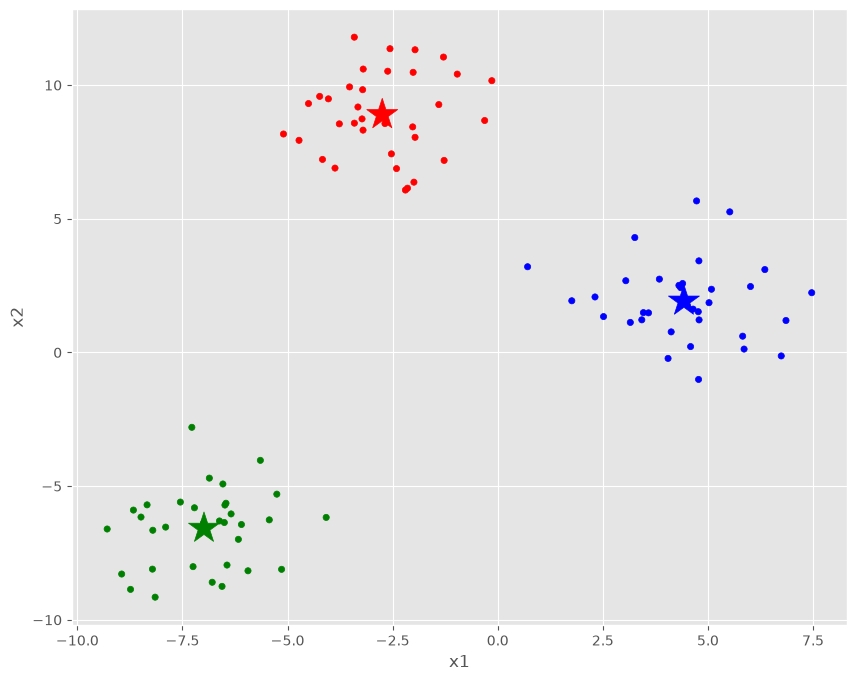

In [215]:
# Create Scatterplot!

# Figsize
plt.figure(figsize=(10,8))

# Map colors for different clusters
colors = ["red", "green", "blue"]
df['color'] = df['cluster'].map(lambda p: colors[p])

# Plot points
ax = df.plot(    
    kind="scatter", 
    x="x1", y="x2",
    figsize=(10,8),
    c = df['color']
)

# Plot Centroids
centroids.plot(
    kind="scatter", 
    x="x1", y="x2", 
    marker="*", c=["r", "g", "b"], s=550, ax=ax
);

---

To the slides!

---

# Metrics for Assessing Clusters
---
## Inertia

Sum of squared differences between each point in a cluster and that cluster's centroid.

How dense is each cluster? 


- low inertia = dense cluster
- ranges from 0 to very high values


$$ \sum_{j=0}^{n} (x_j - \mu_i)^2 $$

where $\mu_i$ is a cluster centroid



`.inertia_` is an attribute of a fitted sklearn's kmeans object

#### Lower inertia is better! Though be cautious with adding too many clusters.

#### Get the inertia

In [216]:
km.inertia_

12.264727255529841

---
## Silhouette Score

Tells you how much closer data points are to their own clusters than to the nearest neighbor cluster.

How far apart are the clusters?
- ranges from -1 to 1
- high silhouette score means the clusters are well separated



### $s_i = \frac{b_i - a_i}{max\{a_i, b_i\}}$

Where:
- $a_i$ = Cohesion: Mean distance of points within a cluster from each other.
- $b_i$ = Separation: Mean distance from point $x_i$ to all points in the next nearest cluster.

Use scikit-learn: `metrics.silhouette_score(X_scaled, labels)`.

#### Higher silhouette score is better!


#### Compute the silhouette score 

In [217]:
from sklearn.metrics import silhouette_score

In [218]:
silhouette_score(X_scaled, labels= km.labels_)

0.7723797723428809

# Using the elbow method to choose _k_
---

The [elbow method](https://en.wikipedia.org/wiki/Elbow_method_(clustering)) is one possible method to help narrow in on the ideal value of **K**. 

### Choose the number of clusters where the next cluster doesn't significantly improve performance. 

#### Let's use the `.interia_` method as our evaluation metric

In [219]:
inertia_list = []

k_list = range(1,15)

for k in k_list:
    model = KMeans(n_clusters=k)
    model.fit(X_scaled)

    inertia_list.append(model.inertia_)

pd.DataFrame({
    'k value' : k_list,
    'inertia value' : inertia_list
})

,k value,inertia value
0,1,200.000000
1,2,67.928747
2,3,12.264727
3,4,10.651398
4,5,9.077745
5,6,7.520858
6,7,6.827930
7,8,5.645196
8,9,5.319782
9,10,4.664981


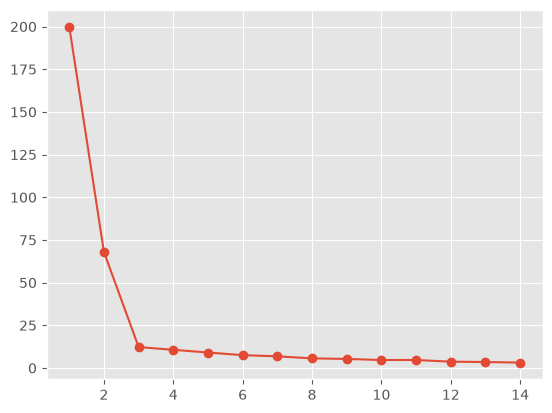

In [220]:
plt.plot(k_list, inertia_list, marker='o')

#### Analyze the above

- Do you see the **"elbow"**?

- What's the best value for _k_?



In [221]:
sil_list = []

k_list = range(2,15)

for k in k_list:
    model = KMeans(n_clusters=k)
    model.fit(X_scaled)

    sil_list.append(silhouette_score(X_scaled, labels= model.labels_))

pd.DataFrame({
    'k value' : k_list,
    'sil value' : sil_list
})


,k value,sil value
0,2,0.646177
1,3,0.772380
2,4,0.605636
3,5,0.460346
4,6,0.449602
5,7,0.368981
6,8,0.338447
7,9,0.350675
8,10,0.338533
9,11,0.358944


<BarContainer object of 13 artists>

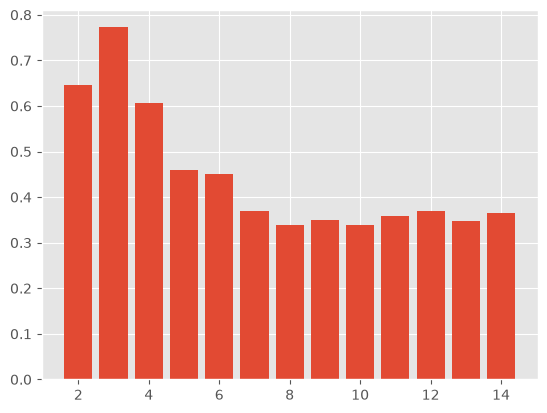

In [222]:
plt.bar(k_list, sil_list)

#### Now let's make a plot with the silhouette score

## Remember: Higher is Better for Silhouette Score!

#### What _k_ should we choose?

# Bonus Exercise 🏋️‍♂️🏋️‍♀️ : Old Faithful
---
The classic Old Faithful dataset describes the durations of eruptions and the amount of waiting time since the last eruption for the Old Faithful geyser. Plot this data. Do you think this data could benefit from clustering? How many clusters are there?

In [223]:
df = pd.read_csv("../data/geyser.csv")
df.head()

,duration,waiting
0,3.600,79
1,1.800,54
2,3.333,74
3,2.283,62
4,4.533,85


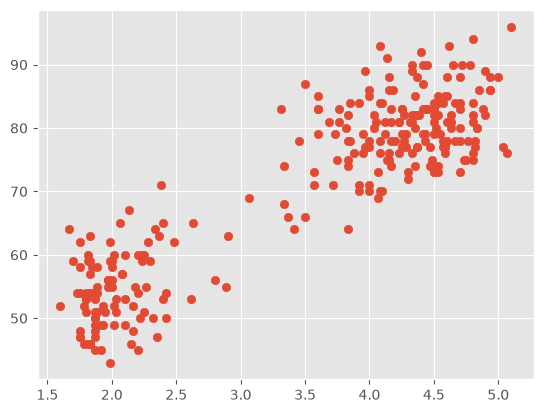

In [224]:
# Plot a scatterplot

plt.scatter(df['duration'], df['waiting'])

In [225]:
# Define X

X = df[['duration', 'waiting']]

In [226]:
# There's a VERY important step before fitting our K-Means Model. Any ideas?
sc = StandardScaler()

X_scaled = sc.fit_transform(X)

In [227]:
# Fit a K-means clustering model
km = KMeans(n_clusters=2, random_state=42)
km.fit(X_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 2)","[

In [228]:
km.labels_

array([0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0,
       0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0,
       0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0,
       0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0,
       0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0,
       1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1,
       0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       1, 1, 0, 0, 1, 0, 1, 0], dtype=int32)

In [229]:
# Add labels to the original dataframe
df['label'] = km.labels_ 

In [230]:
# Create Centroid DataFrame
df

,duration,waiting,label
0,3.600,79,0
1,1.800,54,1
2,3.333,74,0
3,2.283,62,1
4,4.533,85,0
...,...,...,...
267,4.117,81,0
268,2.150,46,1
269,4.417,90,0
270,1.817,46,1


In [235]:
centroids = sc.inverse_transform(km.cluster_centers_)
centroids_df = pd.DataFrame(
    centroids,
    columns= ['duration', 'waiting']
)

<Figure size 1000x800 with 0 Axes>

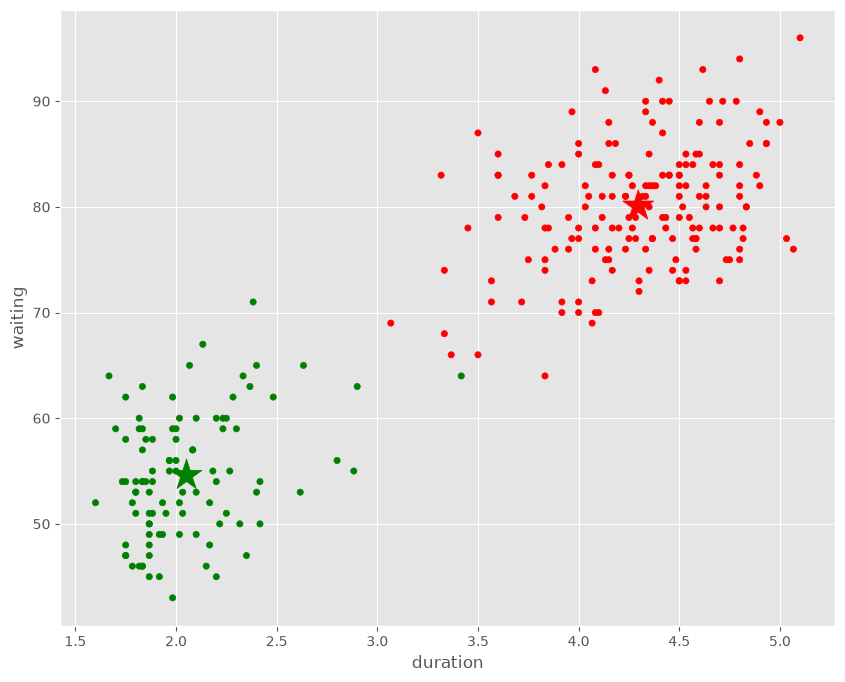

In [236]:
# Create Scatterplot Showing the centroids!

# Figsize
plt.figure(figsize=(10,8))

# Map colors for different clusters
colors = ["red", "green"]
df['color'] = df['label'].map(lambda p: colors[p])

# Plot points
ax = df.plot(    
    kind="scatter", 
    x="duration", y="waiting",
    figsize=(10,8),
    c = df['color']
)

# Plot Centroids
centroids_df.plot(
    kind="scatter", 
    x="duration", y="waiting", 
    marker="*", c=["r", "g"], s=550, ax=ax
);

In [ ]:
# Apply the elbow method


In [ ]:
# Plot the silhouette score against varius clusters



### How many clusters should be used?

# Conclusions and Takeaways
---

Remember that different starting points may give you different clusters. ⚠️ You won't necessarily get an optimal set of clusters!    

You've learned about when and how to use the unsupervised learning clustering algorithm _k-means_. You saw how to save your cluster labels in a DataFrame. You learned several way to evaluate the best number of clusters. 

### Questions...

- What's the main difference between supervised learning and unsupervised learning?
- Why use clustering?
- What does k-means clustering do?
- What does silhouette score measure?

## More Unsupervised learning in the wild

> 1. www.storyblocks.com -- "More Like This" 
> 1. www.amazon.com
> 1. Faces in your photos 

<img src= 'https://support.apple.com/library/content/dam/edam/applecare/images/en_US/iOS/ios15-iphone12-pro-photos-people-album-favorites.png' style='height:500px' />


## Further reading

- The [scikit-learn documentation](http://scikit-learn.org/stable/modules/clustering.html) has a great summary of many other clustering algorithms.
- This [PyData talk](https://www.youtube.com/watch?v=Mf6MqIS2ql4) is good overview of clustering, different algorithms, and how to think about the quality of your clusters.